In [ ]:
from google.colab import drive
import pandas as pd

In [ ]:
aml = drive.mount("/content/drive/")
aml = "/content/drive/MyDrive/aml.csv"
try:
    aml = pd.read_csv(aml)
    print("Success reading aml")
except Exception as e:
    print(type(e).__name__, "-", str(e))


Mounted at /content/drive/
Success reading aml


In [ ]:
aml.head(10)

,date,category,amount_in,amount_out,balance
0,2026-08-21 08:00:44,send_money,0.0,-50.0,808.05
1,2026-08-21 07:44:16,pochi,0.0,-50.0,858.05
2,2026-08-20 15:33:06,pochi,0.0,-30.0,908.05
3,2026-08-20 10:43:49,pochi,0.0,-50.0,938.05
4,2026-08-20 10:25:57,pochi,0.0,-30.0,988.05
5,2026-08-20 08:46:03,pay_bill,0.0,-300.0,1023.05
6,2026-08-20 08:46:03,transaction_fee,0.0,-5.0,1018.05
7,2026-08-19 16:49:58,pay_bill,0.0,-200.0,1328.05
8,2026-08-19 16:49:58,transaction_fee,0.0,-5.0,1323.05
9,2026-08-18 14:27:58,pochi,0.0,-40.0,1528.05


In [ ]:
print(aml.shape)
print(aml.dtypes)

(835, 5)
date           object
category       object
amount_in     float64
amount_out    float64
balance       float64
dtype: object


In [ ]:
aml['date'] = pd.to_datetime(aml['date'], errors="coerce")
print("Unparseable dates include:", aml['date'].isna().sum())
aml = aml.dropna(subset=["date"]).copy()
aml.head()


Unparseable dates include: 0


,date,category,amount_in,amount_out,balance
0,2026-08-21 08:00:44,send_money,0.0,-50.0,808.05
1,2026-08-21 07:44:16,pochi,0.0,-50.0,858.05
2,2026-08-20 15:33:06,pochi,0.0,-30.0,908.05
3,2026-08-20 10:43:49,pochi,0.0,-50.0,938.05
4,2026-08-20 10:25:57,pochi,0.0,-30.0,988.05


In [ ]:
print("Earliest transaction:", aml['date'].min())
print("Latest transaction:", aml['date'].max())
print("Total days", (aml['date'].max()-aml['date'].min() ).days)

Earliest transaction: 2026-01-21 17:03:29
Latest transaction: 2026-08-21 08:00:44
Total days 211


In [ ]:
print(aml['category'].value_counts)
print("Percent 'other':", (aml['category']=='other').mean()*100)

<bound method IndexOpsMixin.value_counts of 0      send_money
1           pochi
2           pochi
3           pochi
4           pochi
          ...    
830         pochi
831         pochi
832         pochi
833    send_money
834         pochi
Name: category, Length: 835, dtype: object>
Percent 'other': 0.0


In [ ]:
for c in ["amount_in", "amount_out", "balance"]:
    aml[c] = pd.to_numeric(aml[c], errors="coerce")
aml["category"] = aml["category"].fillna("other").astype(str).str.strip().str.lower()
aml = aml.sort_values("date").drop_duplicates().reset_index(drop= True)
print("Clean shape:", aml.shape)
print("Date range:", aml["date"].min(), aml["date"].max())
print(aml.isna().sum())


Clean shape: (835, 5)
Date range: 2026-01-21 17:03:29 2026-08-21 08:00:44
date          0
category      0
amount_in     0
amount_out    0
balance       0
dtype: int64


In [ ]:
print("Shape:", aml.shape)
print("Date range:", aml['date'].min(), "to", aml['date'].max())
print("Total Days covered:", (aml['date'].max()-aml['date'].min()).days)
print("\nCategory breakdown:")
print(aml['category'].value_counts())
print("\nPercentage 'other':", (aml['category']=='other').mean()*100, "%")

Shape: (835, 5)
Date range: 2026-01-21 17:03:29 to 2026-08-21 08:00:44
Total Days covered: 211

Category breakdown:
category
pochi               236
send_money          175
transaction_fee     114
buy_goods           104
receive_money        64
data_bundle          41
pay_bill             40
airtime              25
bank_transfer_in     21
agent_withdrawal      8
mshwari_withdraw      5
mshwari_deposit       2
Name: count, dtype: int64

Percentage 'other': 0.0 %


In [ ]:
aml = aml.sort_values('date').reset_index(drop=True)
aml['day'] = aml['date'].dt.date
daily = aml.groupby('day').agg(
    total_out=('amount_out', lambda x: -x.sum()),
    total_in=('amount_in', 'sum'),
    n_transactions=('category','count'),
    end_balance=('balance', 'last')
).reset_index()
print(daily.describe())

          total_out      total_in  n_transactions   end_balance
count    181.000000    181.000000       181.00000    181.000000
mean    1119.364641   1115.906077         4.61326   3860.353867
std     2583.139711   2759.314073         2.73143   3735.497092
min       20.000000      0.000000         1.00000     19.050000
25%      180.000000      0.000000         3.00000    908.050000
50%      350.000000      0.000000         4.00000   2019.050000
75%      612.000000   1200.000000         6.00000   8265.050000
max    20449.000000  20350.000000        18.00000  12918.050000


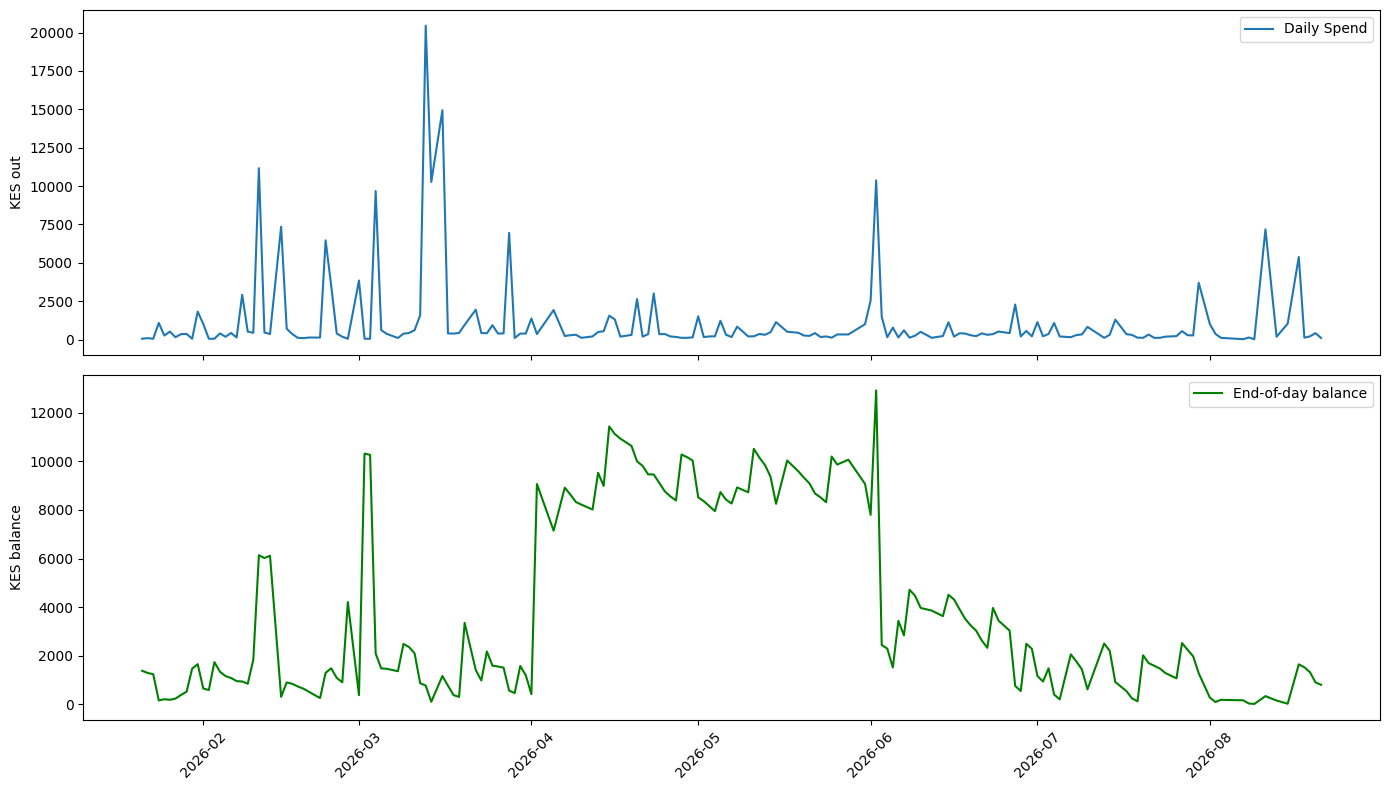


Days with spend > mean + 2 * std (6286 KES):
            day  total_out  total_in  n_transactions  end_balance
21   2026-02-11    11164.0   15400.0               8      6137.05
24   2026-02-15     7354.0    1550.0              18       312.05
32   2026-02-23     6459.0    7500.0               6      1302.05
40   2026-03-04     9675.0    1500.0               8      2092.05
48   2026-03-13    20449.0   20350.0               8       774.05
49   2026-03-14    10266.0    9600.0              14       108.05
50   2026-03-16    14939.0   16000.0              11      1169.05
61   2026-03-28     6944.0    6000.0              12       568.05
116  2026-06-02    10368.0    5500.0               8     12918.05
173  2026-08-11     7178.0    7500.0               9       341.05


In [ ]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2,1,figsize=(14,8), sharex=True)
axes[0].plot(daily['day'], daily['total_out'], label='Daily Spend')
axes[0].set_ylabel('KES out')
axes[0].legend()
axes[1].plot(daily['day'], daily['end_balance'],color='green',  label='End-of-day balance')
axes[1].set_ylabel('KES balance')
axes[1].legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
threshold = daily['total_out'].mean()+ 2 * daily['total_out'].std()
print(f"\nDays with spend > mean + 2 * std ({threshold:.0f} KES):")
print(daily[daily['total_out'] > threshold])

In [ ]:
column_dictionary = {
    "date": "Transaction date parsed from the statement; used for chronological and monthly analysis.",
    "category": "Category assigned by the parser; labels may need manual correction.",
    "amount_in": "Incoming cash-flow amount. This describes money entering M-Pesa, not necessarily earned income.",
    "amount_out": "Outgoing cash-flow amount. This describes money leaving M-Pesa, not necessarily consumption.",
    "balance": "Balance reported by the parser. Confirm its timing and meaning against the original statement before using it.",
}
display(pd.DataFrame.from_dict(column_dictionary, orient="index", columns=["meaning"]).rename_axis("column"))

category_dictionary = {
    "airtime": ("direct_spend_candidate", "Airtime purchase; confirm parser classification."),
    "buy_goods": ("direct_spend_candidate", "Merchant/goods payment; likely consumption."),
    "data_bundle": ("direct_spend_candidate", "Data bundle purchase; likely consumption."),
    "transaction_fee": ("direct_spend_candidate", "Payment fee; count separately or include as a cost."),
    "pay_bill": ("needs_manual_review", "Bill payment; identify what the bill paid for."),
    "pochi": ("needs_manual_review", "Pochi transaction; confirm whether it is a purchase, transfer, or receipt."),
    "agent_withdrawal": ("cash_withdrawal_review", "Cash withdrawal; later cash spending is not visible here."),
    "send_money": ("transfer_or_payment_review", "Money sent; determine recipient/purpose before calling it spending."),
    "mshwari_deposit": ("savings_transfer_candidate", "M-Shwari movement; observed as an outflow, not automatically consumption."),
    "mshwari_withdraw": ("savings_transfer_candidate", "M-Shwari movement; observed as an inflow, not automatically income."),
    "bank_transfer_in": ("inflow_candidate", "Incoming bank transfer; source and purpose are not specified here."),
    "receive_money": ("inflow_candidate", "Incoming receipt; source and purpose are not specified here."),
}

aml["direction"] = "zero_or_invalid"
aml.loc[aml["amount_in"].ne(0), "direction"] = "inflow"
aml.loc[aml["amount_out"].ne(0), "direction"] = "outflow"
aml["candidate_group"] = aml["category"].map(
    {category: details[0] for category, details in category_dictionary.items()}
).fillna("unmapped_review")

category_review = (
    aml.groupby(["category", "candidate_group", "direction"], dropna=False)
    .size()
    .rename("transaction_count")
    .reset_index()
    .sort_values(["candidate_group", "category", "direction"])
)
display(category_review)



,meaning
column,
date,Transaction date parsed from the statement; us...
category,Category assigned by the parser; labels may ne...
amount_in,Incoming cash-flow amount. This describes mone...
amount_out,Outgoing cash-flow amount. This describes mone...
balance,Balance reported by the parser. Confirm its ti...


,category,candidate_group,direction,transaction_count
0,agent_withdrawal,cash_withdrawal_review,outflow,8
1,airtime,direct_spend_candidate,outflow,25
3,buy_goods,direct_spend_candidate,outflow,104
4,data_bundle,direct_spend_candidate,outflow,41
11,transaction_fee,direct_spend_candidate,outflow,114
2,bank_transfer_in,inflow_candidate,inflow,21
9,receive_money,inflow_candidate,inflow,64
7,pay_bill,needs_manual_review,outflow,40
8,pochi,needs_manual_review,outflow,236
5,mshwari_deposit,savings_transfer_candidate,outflow,2


In [ ]:
aml["outflow_kes"] = aml["amount_out"].abs()
aml["month"] = aml["date"].dt.to_period("M").astype(str)
monthly_category_outflow = (

        aml.pivot_table(
            index="month",
            columns="category",
            values="outflow_kes",
            aggfunc="sum",
            fill_value=0,
        ).sort_index()
)
monthly_outflow =(
    monthly_category_outflow.sum(axis=1).rename("total_outflow_kes").to_frame()
)
display(monthly_outflow)
display(monthly_category_outflow)


,total_outflow_kes
month,
2026-01,4779.0
2026-02,37695.0
2026-03,77816.0
2026-04,16762.0
2026-05,11289.0
2026-06,25085.0
2026-07,12905.0
2026-08,16274.0


category,agent_withdrawal,airtime,bank_transfer_in,buy_goods,data_bundle,mshwari_deposit,mshwari_withdraw,pay_bill,pochi,receive_money,send_money,transaction_fee
month,,,,,,,,,,,,
2026-01,1700.0,20.0,0.0,1000.0,0.0,200.0,0.0,0.0,440.0,0.0,1340.0,79.0
2026-02,0.0,80.0,0.0,6380.0,495.0,0.0,0.0,22100.0,1550.0,0.0,6810.0,280.0
2026-03,15900.0,290.0,0.0,5359.0,520.0,0.0,0.0,44160.0,1000.0,0.0,9990.0,597.0
2026-04,0.0,40.0,0.0,5114.0,330.0,0.0,0.0,3460.0,1870.0,0.0,5820.0,128.0
2026-05,500.0,0.0,0.0,3535.0,1000.0,0.0,0.0,900.0,1450.0,0.0,3800.0,104.0
2026-06,500.0,60.0,0.0,1900.0,205.0,0.0,0.0,11230.0,2185.0,0.0,8770.0,235.0
2026-07,0.0,20.0,0.0,2310.0,460.0,0.0,0.0,740.0,1510.0,0.0,7720.0,145.0
2026-08,0.0,80.0,0.0,420.0,290.0,5000.0,0.0,2200.0,650.0,0.0,7500.0,134.0


In [ ]:
from math import sqrt
daily_outflow = (
    aml.set_index("date")["amount_out"].abs().resample("D").sum()

)
holdout_days = 30
if len(daily_outflow) <= holdout_days:
    raise ValueError("Not enough daily history for the specified holdout period.")
split_at = len(daily_outflow) - holdout_days
actual = daily_outflow.iloc[split_at:]
predicted = pd.Series(
    [
        daily_outflow.iloc[max(0, day_index - 30): day_index].mean()
        for day_index in range(split_at, len(daily_outflow))
    ],
    index=actual.index,
    name="predicted_gross_outflow"
)
mae = (actual - predicted).abs().mean()
rmse = sqrt(((actual - predicted) ** 2).mean())
print("Measure: daily gross M-Pesa outflow not confirmed consumption spending")
print(f"Evaluation days:{len(actual)}")
print(f"Holdout period: {actual.index.min().date()} to {actual.index.max().date()}")
print(f"MAE in KES: {mae:.2f}")
print(f"RMSE in KES: {rmse:.2f}")

Measure: daily gross M-Pesa outflow not confirmed consumption spending
Evaluation days:30
Holdout period: 2026-07-23 to 2026-08-21
MAE in KES: 827.55
RMSE in KES: 1693.14


In [ ]:
previous_day_prediction = daily_outflow.shift(1).iloc[split_at:]
previous_day_mae = (actual - previous_day_prediction).abs().mean()
previous_day_rmse = sqrt(((actual - previous_day_prediction) ** 2).mean())
print(f"Previous day MAE in KES: {previous_day_mae:.2f}")
print(f"Previous day RMSE in KES: {previous_day_rmse:.2f}")
print(f"30-day MAE in KES: {mae:.2f}")
print(f"30-day RMSE in KES: {rmse:.2f}")

Previous day MAE in KES: 1284.73
Previous day RMSE in KES: 2511.85
30-day MAE in KES: 827.55
30-day RMSE in KES: 1693.14


In [ ]:
difference_mse = previous_day_mae - mae
difference_rmse =  previous_day_rmse - rmse
print(f"Difference in MAE: {difference_mse:.2f}")
print(f"Difference in RMSE: {difference_rmse:.2f}")

Difference in MAE: 457.18
Difference in RMSE: 818.71


The 30 day rolling average performed better. MAE was lower by Kes 457.18 and RMSE was lower by 818.71

## Synthetic Outflow Dataset
This generates simulated outflow transactions using category frequencies and amount distributions estimated from own  M-Pesa Pilot. Generated rows are synthetic and are not copied transactions. Purposes of the dataset is for testing the pipeline not evidence of perfomance across students

In [ ]:
import numpy as np
import pandas as pd

In [ ]:
required_columns = {"date", "category","amount_out"}
missing_columns = required_columns - set(aml.columns)
if missing_columns:
    raise ValueError(f"aml is missing required columns:{sorted(missing_columns)}")
pilot_outflows = aml.loc[aml["amount_out"] < 0, ["date", "category", "amount_out"]].copy()
pilot_outflows["date"] = pd.to_datetime(pilot_outflows["date"], errors="coerce")
pilot_outflows["category"]= pilot_outflows["category"].astype(str).str.strip().str.lower()
pilot_outflows["amount_kes"] = pilot_outflows["amount_out"].abs()
pilot_outflows = pilot_outflows.dropna(subset=["date", "category", "amount_kes"])
pilot_outflows = pilot_outflows.loc[pilot_outflows["amount_kes"] > 0].copy()
if pilot_outflows.empty:
    raise ValueError("No valid pilot outflows found.")
random_generator = np.random.default_rng(20260930)
number_of_students = 20
simulation_days = 180
injected_anomaly_fraction = 0.01
pilot_start = pilot_outflows["date"].min().normalize()
pilot_end = pilot_outflows["date"].max().normalize()
pilot_calendar_days = (pilot_end - pilot_start).days + 1
mean_daily_transaction_count = len(pilot_outflows) / pilot_calendar_days
category_probabilities = pilot_outflows["category"].value_counts(normalize=True)
category_names = category_probabilities.index.to_numpy()
category_weights = category_probabilities.to_numpy()
amount_parameters = {}
for category, group in pilot_outflows.groupby("category"):
    log_amounts = np.log(group["amount_kes"].to_numpy())
    log_mean = float(log_amounts.mean())
    log_std = float(log_amounts.std(ddof=1)) if len(log_amounts) > 1 else 0.1
    amount_parameters[category] = (log_mean, max(log_std, 0.1))
synthetic_start = pilot_end + pd.Timedelta(days=1)
records=[]
for student_number in range(1, number_of_students + 1):
    student_id = f"SYN{student_number:04d}"
    student_scale = random_generator.lognormal(mean=0.0, sigma = 0.2)
    for day_offset in range(simulation_days):
        transaction_count = random_generator.poisson(mean_daily_transaction_count)
        for _ in range(transaction_count):
                category = random_generator.choice(category_names, p=category_weights)
                log_mean, log_std = amount_parameters[category]
                amount = random_generator.lognormal(log_mean, log_std) * student_scale
                minute_of_day = int(random_generator.integers(0, 24*60))
                timestamp = synthetic_start + pd.Timedelta(days=day_offset, minutes=minute_of_day)
                records.append({
                    "student_id": student_id,
                    "timestamp": timestamp,
                    "category": category,
                    "amount_kes": round(float(amount), 2),
                    "direction": "outflow",
                    "is_anomaly": False,
                    "anomaly_type": "normal",
                    "is_synthetic": True,

                })

synthetic_transactions = pd.DataFrame(records)
if synthetic_transactions.empty:
    raise ValueError("No synthetic transactions were generated.Review frequency and simulation parameters.")
anomaly_count = max(1, int(len(synthetic_transactions) * injected_anomaly_fraction))
anomaly_indices = random_generator.choice(synthetic_transactions.index.to_numpy(), size=min(anomaly_count, len(synthetic_transactions)), replace=False)
synthetic_transactions.loc[anomaly_indices, "is_anomaly"] = True
synthetic_transactions.loc[anomaly_indices, "anomaly_type"] = "injected"
synthetic_transactions.loc[anomaly_indices, "amount_kes"] *= 4
print(f"Synthetic transactions generated: {len(synthetic_transactions)}")
print(f"Synthetic students: {synthetic_transactions['student_id'].nunique()}")
print(f"Synthetic Date Range: {synthetic_transactions['timestamp'].min().date()} to {synthetic_transactions['timestamp'].max().date()}")
print(f"Synthetic anomalies injected: {int(synthetic_transactions['is_anomaly'].sum()):}")
print(f"All rows synthetic: {bool(synthetic_transactions['is_synthetic'].all())}")
display(
    synthetic_transactions.groupby(["category", "is_anomaly"]).size().rename("row_count").reset_index()
)



Synthetic transactions generated: 12322
Synthetic students: 20
Synthetic Date Range: 2026-08-22 to 2027-02-17
Synthetic anomalies injected: 123
All rows synthetic: True


,category,is_anomaly,row_count
0,agent_withdrawal,False,123
1,airtime,False,411
2,airtime,True,2
3,buy_goods,False,1704
4,buy_goods,True,22
5,data_bundle,False,679
6,data_bundle,True,9
7,mshwari_deposit,False,43
8,pay_bill,False,632
9,pay_bill,True,5


In [ ]:
required_synthetic_columns = {
    "student_id", "timestamp", "category", "amount_kes", "direction", "is_anomaly", "anomaly_type", "is_synthetic"
}
missing_columns = required_synthetic_columns - set(synthetic_transactions.columns)
if missing_columns:
    raise ValueError(f"Missing required synthetic columns: {sorted(missing_columns)}")
assert synthetic_transactions["amount_kes"].gt(0).all()
assert synthetic_transactions["direction"].eq("outflow").all()
assert synthetic_transactions["is_synthetic"].all()
assert synthetic_transactions["is_anomaly"].sum() > 0
assert synthetic_transactions["is_anomaly"].sum() == (
    synthetic_transactions["anomaly_type"] != "normal"
).sum()
synthetic_monthly = (synthetic_transactions.assign(
    month=synthetic_transactions["timestamp"].dt.to_period("M").astype("str"),

).groupby(["student_id","month"],as_index=False)["amount_kes"].sum().rename(columns={"amount_kes": "gross_outflow_kes"}).reset_index())
print("Synthetic dataset validation done")
print(f"Rows:{len(synthetic_transactions):,}")
print(f"Students:{(synthetic_transactions['student_id'].nunique())}")
print(f"Monthly students records:{len(synthetic_monthly):,}")
display(synthetic_monthly.groupby("month").size().rename("student_count").to_frame())

Synthetic dataset validation done
Rows:12,322
Students:20
Monthly students records:140


,student_count
month,
2026-08,20
2026-09,20
2026-10,20
2026-11,20
2026-12,20
2027-01,20
2027-02,20


In [ ]:
synthetic_transactions["month"] = synthetic_transactions["month"]=synthetic_transactions["timestamp"].dt.to_period("M").astype(str)
monthly_features =(
    synthetic_transactions.pivot_table (
        index=["student_id", "month"],
        columns="category",
        values="amount_kes",
        aggfunc="sum",
        fill_value=0,
    ).reset_index()
)
monthly_features["gross_outflow_kes"] = monthly_features.drop(
    columns=["student_id", "month"],
).sum(axis=1)
monthly_features = monthly_features.sort_values(["student_id", "month"])
monthly_features["next_monthly_outflow_kes"] = (
    monthly_features.groupby("student_id")
[ "gross_outflow_kes"].shift(-1))
forecasting_dataset = monthly_features.dropna(
    subset=["next_monthly_outflow_kes"]
).reset_index(drop=True)
print(f"Monthly Feature rows: {len(monthly_features):,}")
print(f"Students:{forecasting_dataset['student_id'].nunique()}")
print(f"Feature months:{forecasting_dataset['month'].min()} to {forecasting_dataset['month'].max()}")
display(forecasting_dataset.tail())

Monthly Feature rows: 140
Students:20
Feature months:2026-08 to 2027-01


category,student_id,month,agent_withdrawal,airtime,buy_goods,data_bundle,mshwari_deposit,pay_bill,pochi,send_money,transaction_fee,gross_outflow_kes,next_monthly_outflow_kes
115,SYN0020,2026-09,0.00,40.56,2139.08,254.61,31514.10,6345.61,1374.63,7243.41,251.14,49163.14,32440.82
116,SYN0020,2026-10,10737.07,45.25,3120.31,52.36,0.00,6010.59,1440.32,10909.53,125.39,32440.82,25576.64
117,SYN0020,2026-11,242.11,79.47,868.30,197.17,14077.91,2652.93,1692.56,5516.89,249.30,25576.64,27392.88
118,SYN0020,2026-12,2869.23,51.88,4092.82,211.26,0.00,14034.91,1717.55,4160.57,254.66,27392.88,44393.95
119,SYN0020,2027-01,0.00,10.49,1954.71,496.14,34981.10,2391.70,1019.87,3265.85,274.09,44393.95,7858.99


In [ ]:
months = sorted(forecasting_dataset['month'].unique())
if len(months) < 6:
        raise ValueError("At least 6 usable months are needed for the test, validation, and training sets")
train_months = months[:-2]
validation_month = months[-2]
test_months = months[-1:]
train_data = forecasting_dataset[forecasting_dataset['month'].isin(train_months)].copy()
validation_data = forecasting_dataset[forecasting_dataset['month'].isin([validation_month])].copy()
test_data = forecasting_dataset[forecasting_dataset['month'].isin(test_months)].copy()
print(f"Train months:{train_months}")
print(f"Validation month:{validation_month}")
print(f"Test months:{test_months}")
print(f"Train data rows:{len(train_data)}")
print(f"Validation data rows:{len(validation_data)}")
print(f"Test data rows:{len(test_data)}")

Train months:['2026-08', '2026-09', '2026-10', '2026-11']
Validation month:2026-12
Test months:['2027-01']
Train data rows:80
Validation data rows:20
Test data rows:20


In [ ]:
excluded_columns =["student_id", "month", "next_monthly_outflow_kes"]
feature_columns = [
    column for column in forecasting_dataset.columns
    if column not in excluded_columns
]
x_train = train_data[feature_columns]
y_train = train_data["next_monthly_outflow_kes"]
x_validation= validation_data[feature_columns]
y_validation = validation_data["next_monthly_outflow_kes"]
x_test = test_data[feature_columns]
y_test = test_data["next_monthly_outflow_kes"]

print("Features:", feature_columns)
print("Training features shape", x_train.shape)
print("Validation features shape", x_validation.shape)
print("Test features shape", x_test.shape)


Features: ['agent_withdrawal', 'airtime', 'buy_goods', 'data_bundle', 'mshwari_deposit', 'pay_bill', 'pochi', 'send_money', 'transaction_fee', 'gross_outflow_kes']
Training features shape (80, 10)
Validation features shape (20, 10)
Test features shape (20, 10)


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
training_mean = y_train.mean()
baseline_prediction = np.full(len(y_test), training_mean)
baseline_mae = mean_absolute_error(y_test, baseline_prediction)
baseline_mse = mean_squared_error(y_test, baseline_prediction)
baseline_rmse = np.sqrt(baseline_mse)
print(f"Monthly Baseline Mae: {baseline_mae:.2f}KES")
print(f"Monthly Baseline RMSE: {baseline_rmse:.2f} KES")


Monthly Baseline Mae: 21639.44KES
Monthly Baseline RMSE: 22708.90 KES


In [ ]:
from sklearn.ensemble import RandomForestRegressor
random_forest = RandomForestRegressor(
    n_estimators=100,
    random_state=20260930,
    n_jobs=-1,
    min_samples_leaf=2
)
random_forest.fit(x_train, y_train)
validation_prediction = random_forest.predict(x_validation)
validation_mae = mean_absolute_error(y_validation, validation_prediction)
validation_rmse = np.sqrt(mean_squared_error(y_validation, validation_prediction))
print(f"Random Forest Validation MAE: {validation_mae}")
print(f"Random Forest Validation RMSE: {validation_rmse}")
print(f"Baseline Validation MAE: {baseline_mae}")
print(f"Baseline Validation RMSE: {baseline_rmse}")

Random Forest Validation MAE: 25303.981868825398
Random Forest Validation RMSE: 32363.870888759324
Baseline Validation MAE: 21639.443625
Baseline Validation RMSE: 22708.895389278667


In [ ]:
validation_baseline_prediction  = np.full(
    len(y_validation),
    training_mean
)
validation_baseline_mae = mean_absolute_error(y_validation, validation_baseline_prediction)
validation_baseline_rmse = np.sqrt(mean_squared_error(y_validation, validation_baseline_prediction))
print(f"Baseline Validation MAE: {validation_baseline_mae:.2f}")
print(f"Baseline Validation RMSE: {validation_baseline_rmse:.2f}")
print(f"Random Forest Validation MAE: {validation_mae:.2f}")
print(f"Random Forest Validation RMSE: {validation_rmse:.2f}")

Baseline Validation MAE: 16510.73
Baseline Validation RMSE: 25548.40
Random Forest Validation MAE: 25303.98
Random Forest Validation RMSE: 32363.87


In [ ]:
random_forest_settings=[
 {"n_estimators":100, "min_samples_leaf":1, "max_features":1.0},
 {"n_estimators":200, "min_samples_leaf":1, "max_features":1.0},
 {"n_estimators":200, "min_samples_leaf":2, "max_features":1.0},
 {"n_estimators":200, "min_samples_leaf":4, "max_features":1.0},
 {"n_estimators":200, "min_samples_leaf":2, "max_features":'sqrt'},
]
tuning_results = []
for settings in random_forest_settings:
    candidate_model = RandomForestRegressor(
        random_state=20260930,
        n_jobs=-1,
        **settings
    )
    candidate_model.fit(x_train,y_train)
    candidate_prediction= candidate_model.predict(x_validation)
    candidate_mae = mean_absolute_error(y_validation, candidate_prediction)
    candidate_rmse = np.sqrt(
        mean_squared_error(y_validation, candidate_prediction)
    )
    tuning_results.append(
        {
            **settings,
            "validation_mae":candidate_mae,
            "validation_rmse":candidate_rmse
        }
    )
tuning_results = pd.DataFrame(tuning_results).sort_values("validation_mae")
display(tuning_results)
print(tuning_results)
print(f"Baseline validation MAE: {validation_baseline_mae}, RMSE: {validation_baseline_rmse}")

,n_estimators,min_samples_leaf,max_features,validation_mae,validation_rmse
3,200,4,1.0,22831.021092,29917.775425
4,200,2,sqrt,23978.707396,31007.967541
2,200,2,1.0,25148.098856,32144.877835
1,200,1,1.0,25966.783060,34247.806308
0,100,1,1.0,26140.288245,35041.528715


   n_estimators  min_samples_leaf max_features  validation_mae  \
3           200                 4          1.0    22831.021092   
4           200                 2         sqrt    23978.707396   
2           200                 2          1.0    25148.098856   
1           200                 1          1.0    25966.783060   
0           100                 1          1.0    26140.288245   

   validation_rmse  
3     29917.775425  
4     31007.967541  
2     32144.877835  
1     34247.806308  
0     35041.528715  
Baseline validation MAE: 16510.7295625, RMSE: 25548.397360006693


Baseline Dataset perfomed better than the Random Forest Candidate therefore no need to use Test set to keep tuning

In [ ]:
train_validation_data = pd.concat([train_data, validation_data], ignore_index=True)
x_train_validation = train_validation_data[feature_columns]
y_train_validation = train_validation_data["next_monthly_outflow_kes"]

final_random_forest = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=4,
    max_features=1.0,
    random_state=20260930,
    n_jobs=-1
)
final_random_forest.fit(x_train_validation, y_train_validation)
test_prediction = final_random_forest.predict(x_test)
test_baseline_predictions = np.full(len(y_test), y_train_validation.mean())
rf_test_mae = mean_absolute_error(y_test, test_prediction)
rf_test_rmse = np.sqrt(mean_squared_error(y_test,test_prediction))
baseline_test_mae = mean_absolute_error(y_test, test_baseline_predictions)
baseline_test_rmse = np.sqrt(mean_squared_error(y_test, test_baseline_predictions))
print(f"Test Period: {test_data['month'].min()} to {test_data['month'].max()}")
print(f"Random Forest Test MAE: {rf_test_mae:.2f} KES")
print(f"Random Forest Test RMSE: {rf_test_rmse:.2f} KES")
print(f"Baseline Test MAE: {baseline_test_mae:.2f} KES")
print(f"Baseline Test RMSE: {baseline_test_rmse:.2f} KES")

Test Period: 2027-01 to 2027-01
Random Forest Test MAE: 25727.37 KES
Random Forest Test RMSE: 29193.07 KES
Baseline Test MAE: 20890.45 KES
Baseline Test RMSE: 21996.34 KES


Test Period: 2027-01 to 2027-01
Random Forest Test MAE: 25727.37 KES
Random Forest Test RMSE: 29193.07 KES
Baseline Test MAE: 20890.45 KES
Baseline Test RMSE: 21996.34 KES
### Random Forest configuration did not outperform the baseline on the synthetic test data

In [ ]:
from xgboost import XGBRegressor
xgboost_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=100,
    max_depth=2,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=20260930,
    n_jobs=-1
)
xgboost_model.fit(x_train, y_train)
xgboost_validation_prediction = xgboost_model.predict(x_validation)
xgboost_validation_mae = mean_absolute_error(
    y_validation,
    xgboost_validation_prediction
)
xgboost_validation_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        xgboost_validation_prediction
    )
)
print(f"XGBoost Validation MAE: {xgboost_validation_mae:.2f} KES")
print(f"XGBoost Validation RMSE: {xgboost_validation_rmse:.2f} KES")
print(f"Baseline validation MAE: {validation_baseline_mae:.2f} KES")
print(f"Baseline validation RMSE: {validation_baseline_rmse:.2f} KES")

XGBoost Validation MAE: 31065.57 KES
XGBoost Validation RMSE: 42440.68 KES
Baseline validation MAE: 16510.73 KES
Baseline validation RMSE: 25548.40 KES


In [ ]:
best_random_forests_model = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=4,
    max_features=1.0,
    random_state=20260930,
    n_jobs=-1
)
best_random_forests_model.fit(x_train, y_train)
random_forest_validation_prediction = best_random_forests_model.predict(x_validation)
ensemble_validation_prediction = (
    (xgboost_validation_prediction + random_forest_validation_prediction) / 2
)
ensemble_validation_mae = mean_absolute_error(y_validation, ensemble_validation_prediction)
ensemble_validation_rmse = np.sqrt(
    mean_squared_error(y_validation, ensemble_validation_prediction)
)
print(f"Ensemble Validation MAE: {ensemble_validation_mae:.2f} KES")
print(f"Ensemble Validation RMSE: {ensemble_validation_rmse:.2f} KES")
print(f"Baseline validation MAE: {validation_baseline_mae:.2f} KES")
print(f"Baseline validation RMSE: {validation_baseline_rmse:.2f} KES")

Ensemble Validation MAE: 26807.40 KES
Ensemble Validation RMSE: 35197.68 KES
Baseline validation MAE: 16510.73 KES
Baseline validation RMSE: 25548.40 KES


### On the synthetic validation set, using December 2026 features to predict January 2027 gross outflow, the baseline outperformed the 50/50 Random Forest/XGBoost ensemble on both MAE and RMSE.

## Anomaly Detection

In [ ]:
anomaly_data = synthetic_transactions.copy()
anomaly_data["timestamp"] = pd.to_datetime(anomaly_data["timestamp"])
anomaly_data["event_date"] = anomaly_data["timestamp"].dt.normalize()
unique_dates = np.sort(anomaly_data["event_date"].unique())
if len(unique_dates) < 20:
    raise ValueError("Not enough unique dates for chronological anomaly splits")
train_cutoff = unique_dates[int(len(unique_dates)*0.7) - 1]
validation_cutoff = unique_dates[int(len(unique_dates)*0.85) - 1]
anomaly_train = anomaly_data[anomaly_data["event_date"] <= train_cutoff].copy()
anomaly_validation = anomaly_data[(anomaly_data["event_date"] > train_cutoff) & (anomaly_data["event_date"] <= validation_cutoff)].copy()
anomaly_test = anomaly_data[anomaly_data["event_date"] > validation_cutoff].copy()

for split_name, split_data in [
    ("train", anomaly_train),
    ("validation", anomaly_validation),
    ("test", anomaly_test)
]:
    print(
        f"{split_name} split: {len(split_data)} rows",
        f"{split_data['event_date'].min()} to {split_data['event_date'].max()}",
        f"{int(split_data['is_anomaly'].sum())} injected anomalies"
    )
    assert not anomaly_train.empty
    assert not anomaly_validation.empty
    assert not anomaly_test.empty
    assert anomaly_train["is_anomaly"].sum() < len(anomaly_train)

train split: 8527 rows 2026-08-22 00:00:00 to 2026-12-24 00:00:00 87 injected anomalies
validation split: 1949 rows 2026-12-25 00:00:00 to 2027-01-21 00:00:00 17 injected anomalies
test split: 1846 rows 2027-01-22 00:00:00 to 2027-02-17 00:00:00 19 injected anomalies


In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_recall_curve, precision_score, f1_score, recall_score
feature_input_columns = ["amount_kes", "category"]
x_train_raw = pd.get_dummies(
    anomaly_train[feature_input_columns],
    columns = ["category"],
    dtype=float
)
x_validation_raw = pd.get_dummies(
    anomaly_validation[feature_input_columns],
    columns = ["category"],
    dtype=float
).reindex(columns=x_train_raw.columns, fill_value=0)
x_test_raw = pd.get_dummies(
    anomaly_test[feature_input_columns],
    columns = ["category"],
    dtype=float
).reindex(columns=x_train_raw.columns, fill_value=0)
normal_train_mask = ~anomaly_train["is_anomaly"].astype(bool)
x_train_normal = x_train_raw[normal_train_mask]
scaler = StandardScaler()
X_train_normal_scaled = scaler.fit_transform(x_train_normal)
pca_model = PCA(n_components=0.95, svd_solver="full")
pca_model.fit(X_train_normal_scaled)
def reconstruction_error(features):
    scaled_features = scaler.transform(features)
    reconstructed = pca_model.inverse_transform(
        pca_model.transform(scaled_features)
    )
    return np.mean((scaled_features - reconstructed) ** 2, axis=1)
validation_scores = reconstruction_error(x_validation_raw)
test_scores = reconstruction_error(x_test_raw)
y_validation_anomaly = anomaly_validation["is_anomaly"].astype(bool).to_numpy()
y_test_anomaly = anomaly_test["is_anomaly"].astype(bool).to_numpy()
precision_values, recall_values, thresholds = precision_recall_curve(
    y_validation_anomaly, validation_scores
)
validation_f1_scores = (
    2 * precision_values[:-1]  * recall_values[:-1] / (precision_values[:-1]+ recall_values[:-1] + 1e-12)
)
best_threshold_index = int(np.argmax(validation_f1_scores))
anomaly_threshold = thresholds[best_threshold_index]
validation_predictions = validation_scores >= anomaly_threshold
test_predictions = test_scores >= anomaly_threshold
print(f"PCA components retained: {pca_model.n_components_}")
print(f"Selected validation threshold: {anomaly_threshold:.3f}")
print(f"Validation precision: {precision_score(y_validation_anomaly, validation_predictions, zero_division=0):.3f}")
print(f"Validation recall: {recall_score(y_validation_anomaly, validation_predictions, zero_division=0):.3f}")
print(f"Validation F1 score: {f1_score(y_validation_anomaly, validation_predictions, zero_division=0):.3f}")
print(f"Test precision: {precision_score(y_test_anomaly, test_predictions, zero_division=0):.3f}")
print(f"Test recall: {recall_score(y_test_anomaly, test_predictions, zero_division=0):.3f}")
print(f"Test F1 score: {f1_score(y_test_anomaly, test_predictions, zero_division=0):.3f}")





PCA components retained: 9
Selected validation threshold: 0.000
Validation precision: 0.016
Validation recall: 0.118
Validation F1 score: 0.028
Test precision: 0.014
Test recall: 0.105
Test F1 score: 0.025


Test precision of 0.014 means that only about 1 in 71 predictions is correct.
Test recall of 0.105 means that only about 2 of the 19 injected anomalies are correctly identified.

In [ ]:
import random
import torch
import torch.nn as nn
from sklearn.cluster import Birch
from sklearn.metrics import pairwise_distances_argmin_min
from sklearn.metrics import precision_recall_curve, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler

seed = 20260930
random.seed(seed)
torch.manual_seed(seed)
np.random.seed(seed)
device = torch.device("cpu")
normal_train_mask = ~anomaly_train["is_anomaly"].astype(bool)
bae_scaler = StandardScaler()
x_train_normal_scaled = bae_scaler.fit_transform(
    x_train_raw.loc[normal_train_mask]
).astype(np.float32)
x_validation_scaled = bae_scaler.transform(
    x_validation_raw
).astype(np.float32)
x_test_scaled = bae_scaler.transform(x_test_raw).astype(np.float32)
input_dim = x_train_normal_scaled.shape[1]
hidden_dim = max(8, min(64, input_dim * 2))
latent_dim = max(2, min(8, input_dim // 2))
class Autoencoder(nn.Module):
    def __init__(self, input_size, hidden_size, latent_size):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, latent_size)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, input_size)
        )

    def forward(self, values):
        latent = self.encoder(values)
        return self.decoder(latent)

autoencoder = Autoencoder(input_dim, hidden_dim, latent_dim).to(device)
train_tensor = torch.from_numpy(x_train_normal_scaled).to(device)
optimizer = torch.optim.Adam(autoencoder.parameters(), lr=0.001)
loss_function = nn.MSELoss()
training_epochs = 100
autoencoder.train()
for epoch in range(training_epochs):
    optimizer.zero_grad()
    reconstructed = autoencoder(train_tensor)
    loss = loss_function(reconstructed, train_tensor)
    loss.backward()
    optimizer.step()
autoencoder.eval()

def get_bae_components(scaled_features):
    feature_tensor = torch.from_numpy(
        np.asarray(scaled_features, dtype=np.float32)
    ).to(device)
    with torch.no_grad():
        latent_values = autoencoder.encoder(feature_tensor)
        reconstructed_values = autoencoder(feature_tensor)
    reconstruction_scores = torch.mean(
        (feature_tensor - reconstructed_values) ** 2, dim=1
    ).cpu().numpy()
    latent_values = latent_values.cpu().numpy()
    return reconstruction_scores, latent_values

# Clustering
train_reconstruction_scores, train_latent = get_bae_components(x_train_normal_scaled)
latent_scaler = StandardScaler()
train_latent_scaled = latent_scaler.fit_transform(train_latent)
birch_model = Birch(threshold=0.5,n_clusters=None)
birch_model.fit(train_latent_scaled)
birch_centers = birch_model.subcluster_centers_.copy()

def get_bae_scores(scaled_features):
    reconstruction_scores, latent_values = get_bae_components(scaled_features)
    latent_values_scaled = latent_scaler.transform(latent_values)
    _, cluster_distances = pairwise_distances_argmin_min(
        latent_values_scaled,
        birch_centers,
    )
    return reconstruction_scores, cluster_distances
train_reconstruction_scores, train_cluster_scores = get_bae_scores(x_train_normal_scaled)
validation_reconstruction_scores, validation_cluster_scores = get_bae_scores(x_validation_scaled)
test_reconstruction_scores, test_cluster_scores = get_bae_scores(x_test_scaled)

def robust_score_scale(values, reference_values):
    median = np.median(reference_values)
    spread = np.percentile(reference_values, 75) - np.percentile(reference_values, 25)
    if spread <= 1e-12:
        spread = np.std(reference_values)
        if spread <= 1e-12:
            spread = 1.0
    return (values - median) / spread
train_reconstruction_scaled = robust_score_scale(
    train_reconstruction_scores, train_reconstruction_scores
)
train_cluster_scaled = robust_score_scale(
    train_cluster_scores, train_cluster_scores
)
validation_bae_scores = (
    robust_score_scale(validation_reconstruction_scores, train_reconstruction_scores) +
    robust_score_scale(validation_cluster_scores, train_cluster_scores)
)/2
test_bae_scores = (
    robust_score_scale(test_reconstruction_scores, train_reconstruction_scores) +
    robust_score_scale(test_cluster_scores, train_cluster_scores)
)/2

y_validation_anomaly = anomaly_validation["is_anomaly"].astype(bool).to_numpy()
y_test_anomaly = anomaly_test["is_anomaly"].astype(bool).to_numpy()

precision_values, recall_values, thresholds = precision_recall_curve(
    y_validation_anomaly, validation_bae_scores
)
validation_f1_scores = (
    2 *(precision_values[:-1] * recall_values[:-1])/(precision_values[:-1]+ recall_values[:-1]+ 1e-12)
)
best_threshold_index = int(np.argmax(validation_f1_scores))
bae_threshold = thresholds[best_threshold_index]
validation_bae_predictions = validation_bae_scores >= bae_threshold
test_bae_predictions = test_bae_scores >= bae_threshold

print(f"Autoencoder input features:{input_dim}")
print(f"Latent dimension:{latent_dim}")
print(f"BIRCH subclusters:{len(birch_centers)}")
print(f"Selected validation threshold:{bae_threshold:.3e}")
print(f"Validation precision:{precision_score(y_validation_anomaly, validation_bae_predictions, zero_division=0)}")
print(f"Validation recall:{recall_score(y_validation_anomaly, validation_bae_predictions, zero_division=0)}")
print(f"Validation F1:{f1_score(y_validation_anomaly, validation_bae_predictions, zero_division=0)}")

print(f"Test precision:{precision_score(y_test_anomaly, test_bae_predictions, zero_division=0)}")
print(f"Test recall:{recall_score(y_test_anomaly, test_bae_predictions, zero_division=0)}")
print(f"Test F1:{f1_score(y_test_anomaly, test_bae_predictions, zero_division=0)}")


Autoencoder input features:10
Latent dimension:5
BIRCH subclusters:31
Selected validation threshold:1.744e+00
Validation precision:0.02857142857142857
Validation recall:0.058823529411764705
Validation F1:0.038461538461538464
Test precision:0.0
Test recall:0.0
Test F1:0.0


In [ ]:
print(f"BAE test alerts:{int(test_bae_predictions.sum())}")
print(f"Injected test anomalies:{int(y_test_anomaly.sum())}")
print(f"True positive alerts:{int((test_bae_predictions & y_test_anomaly).sum())}")

BAE test alerts:36
Injected test anomalies:19
True positive alerts:0


### BAE thresholds produced 36 test alerts, all false positives while missing all 19 injected anomalies(false negatives).

## MLP Forecasting

In [ ]:
import copy
from sklearn.preprocessing import StandardScaler

seed = 20260930
np.random.seed(seed)
torch.manual_seed(seed)
device = torch.device("cpu")

mlp_x_scaler = StandardScaler()
x_train_scaled = mlp_x_scaler.fit_transform(x_train).astype(np.float32)
x_validation_scaled = mlp_x_scaler.transform(x_validation).astype(np.float32)
mlp_y_scaler = StandardScaler()
y_train_scaled = mlp_y_scaler.fit_transform(y_train.to_numpy().reshape(-1,1)).astype(np.float32)
y_validation_scaled = mlp_y_scaler.transform(y_validation.to_numpy().reshape(-1,1)).astype(np.float32)
x_train_tensor = torch.from_numpy(x_train_scaled).to(device)
y_train_tensor = torch.from_numpy(y_train_scaled).to(device)
x_validation_tensor = torch.from_numpy(x_validation_scaled).to(device)
y_validation_tensor = torch.from_numpy(y_validation_scaled).to(device)

class BudgetMLP(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 16),
            nn.ReLU(),
            nn.Linear(16,1)
        )
    def forward(self, values):
        return self.network(values)
mlp_model = BudgetMLP(x_train_tensor.shape[1]).to(device)
mlp_optimizer = torch.optim.Adam(
    mlp_model.parameters(),
    lr=0.001,
    weight_decay= 0.001
)
mlp_loss_function = nn.MSELoss()
best_validation_mae_scaled = float("inf")
best_mlp_state = None
epochs_without_improvement = 0
early_stopping_patience = 20

for epoch in range(500):
    mlp_model.train()
    mlp_optimizer.zero_grad()
    train_predictions = mlp_model(x_train_tensor)
    train_loss = mlp_loss_function(train_predictions, y_train_tensor)
    train_loss.backward()
    mlp_optimizer.step()

    mlp_model.eval()
    with torch.no_grad():
        validation_prediction_scaled = mlp_model(x_validation_tensor)
        current_validation_mae_scaled = torch.mean(
            torch.abs(validation_prediction_scaled - y_validation_tensor)
        ).item()
        if current_validation_mae_scaled < best_validation_mae_scaled:
            best_validation_mae_scaled = current_validation_mae_scaled
            best_mlp_state = copy.deepcopy(mlp_model.state_dict())
            best_epoch = epoch + 1
            epochs_without_improvement = 0
        else:
            epochs_without_improvement +=1
        if epochs_without_improvement >= early_stopping_patience:
            print(f"Early stopping at epoch {epoch + 1}")
            break
mlp_model.load_state_dict(best_mlp_state)
mlp_model.eval()
with torch.no_grad():
    mlp_validation_prediction_scaled = mlp_model(x_validation_tensor).cpu().numpy()
mlp_validation_prediction = mlp_y_scaler.inverse_transform(mlp_validation_prediction_scaled).ravel()
mlp_validation_mae = mean_absolute_error(y_validation, mlp_validation_prediction)
mlp_validation_rmse = np.sqrt(mean_squared_error(y_validation, mlp_validation_prediction))

print(f"Best epoch:{best_epoch}")
print(f"MLP Validation MAE:{mlp_validation_mae:.2f} KES")
print(f"MLP Validation RMSE:{mlp_validation_rmse:.2f} KES")
print(f"Baseline validation MAE:{validation_baseline_mae:.2f} KES")
print(f"Baseline validation RMSE:{validation_baseline_rmse:.2f} KES")






Early stopping at epoch 65
Best epoch:45
MLP Validation MAE:16004.86 KES
MLP Validation RMSE:26014.19 KES
Baseline validation MAE:16510.73 KES
Baseline validation RMSE:25548.40 KES


Early stopping at epoch 65

Best epoch:45

MLP Validation MAE:16,004.86 KES about 3.1% better than the baseline 16,510 KES

MLP Validation RMSE:26,014.19 KES about 1.8% worse than the baseline KES 25,548.40 KES



In [ ]:
test